# Лабораторная работа №1
## Иерархический кластерный анализ
Манухин Константин  
Вариант 2 - Экономика городов  

**Цель работы** - познакомиться с работой алгоритма иерархического кластерного анализа на примере анализа городов по экономическим показателям

Гипотезы:
- Города могут быть похожи друг на друга по экономическим параметрам, поэтому их можно разбить на кластеры
- В данных будут выбросы - города с сильно отличающимися условиями от остальных

Описание данных:
- Название города
- Среднее рабочих часов по 12 профессиям
- Индекс цен на 112 товаров и услуг
- Индекс зарплаты за час работы после вычета налогов


# Подготовка
Импортируем данные, найдем выбросы, стандартизируем

In [1]:
# Импорт библиотек
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gdown
import itertools
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

from scipy.cluster.hierarchy import dendrogram, linkage, fcluster, cophenet
from scipy.spatial.distance import pdist

In [2]:
# Константы
RANDOM_STATE = 42 # сид рандома для воспроизводимости
FILENAME = "data.csv"
NAME_COL = "City"
NUM_COLS = ["Work", "Price", "Salary"]

In [3]:
# Загрузка данных с гугл-диска
def download_data(file_id: str, filename: str, sep: str=";", dec: str=","):
    url = f"https://drive.google.com/uc?id={file_id}"
    gdown.download(url, filename)
    return pd.read_csv(FILENAME, sep=sep, decimal=dec)


# Ссылка на данные - https://drive.google.com/file/d/1CeHPnsBl7XGlnxzSryNnYx1FteILxOdM/view?usp=drive_link
# Из файла видно, что разделитель колонок - ";" а для дробных - ","
file_id = "1CeHPnsBl7XGlnxzSryNnYx1FteILxOdM"
df = download_data(file_id, FILENAME)
df.head(3)

Downloading...
From: https://drive.google.com/uc?id=1CeHPnsBl7XGlnxzSryNnYx1FteILxOdM
To: /content/data.csv
100%|██████████| 1.18k/1.18k [00:00<00:00, 952kB/s]


,City,Work,Price,Salary
0,Amsterdam,1714,65.6,49.0
1,Athens,1792,53.8,30.4
2,Bogota,2152,37.9,11.5


In [4]:
# Типы данных загрузились правильно
df.dtypes

,0
City,object
Work,int64
Price,float64
Salary,float64


In [5]:
# Данные - 48 городов: имя + 3 числовых параметра
print(df.shape)
df.head(3)

(48, 4)


,City,Work,Price,Salary
0,Amsterdam,1714,65.6,49.0
1,Athens,1792,53.8,30.4
2,Bogota,2152,37.9,11.5


In [6]:
# Нет пропусков. Возможно они заменены на какое-то значение
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   City    48 non-null     object 
 1   Work    48 non-null     int64  
 2   Price   48 non-null     float64
 3   Salary  48 non-null     float64
dtypes: float64(2), int64(1), object(1)
memory usage: 1.6+ KB


In [7]:
# Статистики по данным
def desc(df: pd.DataFrame, r: int=2):
    return df[NUM_COLS].describe().round(r)

# Посмотрим на статистики - подозрительное значение "-9999"
# Из-за них некоторые статистики уехали в отрицательный диапазон
desc(df)

,Work,Price,Salary
count,48.00,48.00,48.00
mean,1384.96,68.86,-378.73
std,2404.90,21.78,2027.34
min,-9999.00,30.30,-9999.00
25%,1740.75,49.65,12.25
50%,1834.50,70.50,40.30
75%,1972.75,81.70,58.70
max,2375.00,115.50,100.00


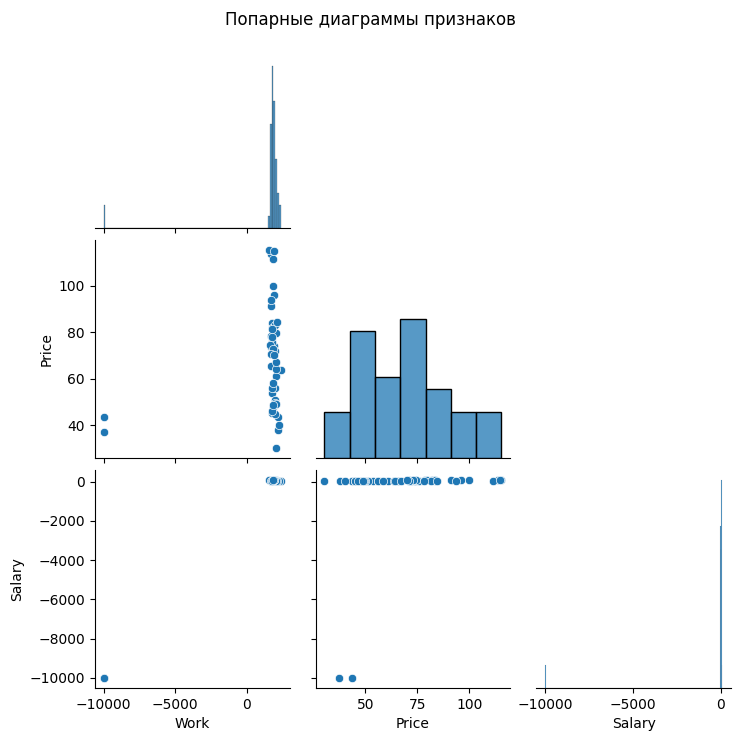

In [8]:
# Отображение попарных графиков
def pairs(df: pd.DataFrame):
    g = sns.pairplot(df, corner=True)
    g.fig.suptitle("Попарные диаграммы признаков")
    return g

# На графиках видно, что эти выбросы в -9999 портят вся картину
pairs(df)

In [9]:
# У Каира и Джакарты 2 из 3 значений = -9999.
# Предлагаю просто отбросить эти строки
df[df.eq(-9999).any(axis=1)]

,City,Work,Price,Salary
6,Cairo,-9999,37.1,-9999.0
17,Jakarta,-9999,43.6,-9999.0


In [10]:
# Удаление строк с определенным значением
def clean_data(df: pd.DataFrame, filter_value: int):
    mask = ~df.eq(filter_value).any(axis=1)
    return df[mask].reset_index(drop=True)

# Удаляем выбросы
df_filtered = clean_data(df, -9999)
print(df_filtered.shape)
df_filtered.head(3)

(46, 4)


,City,Work,Price,Salary
0,Amsterdam,1714,65.6,49.0
1,Athens,1792,53.8,30.4
2,Bogota,2152,37.9,11.5


Отобразим статистики и графики - данные выглядят вполне себе нормально, без выбросов


In [11]:
# Статистики
desc(df_filtered)

,Work,Price,Salary
count,46.00,46.00,46.00
mean,1879.91,70.10,39.55
std,174.34,21.39,24.76
min,1583.00,30.30,2.70
25%,1745.25,51.78,14.38
50%,1849.00,70.95,43.65
75%,1976.25,81.90,59.70
max,2375.00,115.50,100.00


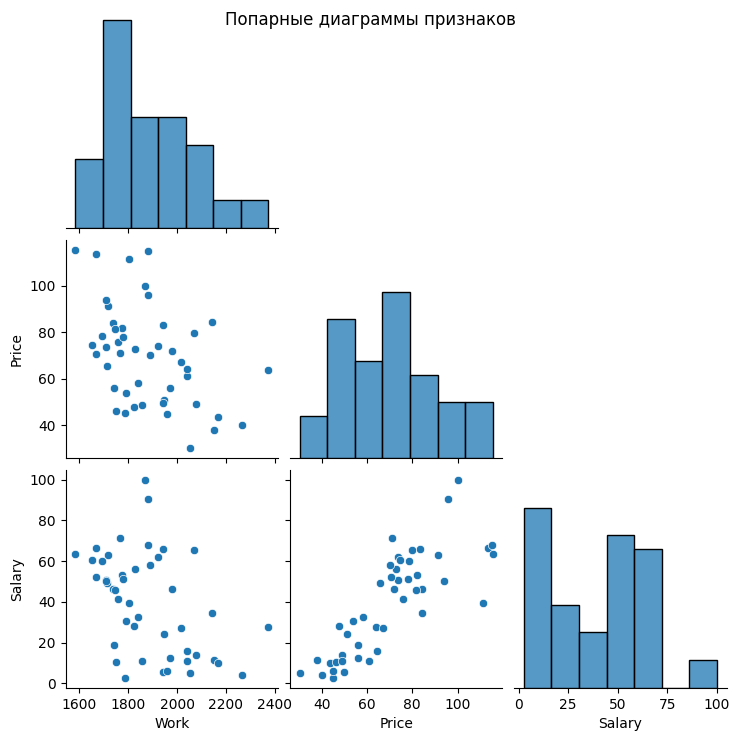

In [12]:
# Парные диаграммы
pairs(df_filtered)

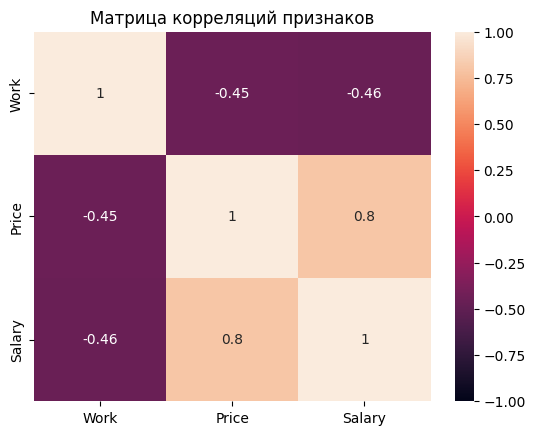

In [13]:
# Отображение матрицы корреляций признаков
def heatmap(df: pd.DataFrame):
    corr = df[NUM_COLS].corr()
    sns.heatmap(corr, annot=True, vmin=-1, vmax=1)
    plt.title("Матрица корреляций признаков")

# Корреляции - похоже что цены связвны с зарплатами.
# Логично, люди могут позволить себе больше
heatmap(df_filtered)

In [14]:
# Скейлинг данных
def scale_data(df: pd.DataFrame):
    scaler = StandardScaler()
    df_new = df.copy()
    df_new[NUM_COLS] = scaler.fit_transform(df[NUM_COLS])
    return df_new

# Сразу подготовим стандартизарованный набор данных
df_scaled = scale_data(df_filtered)
print(df_scaled.shape)
df_scaled.head(3)

(46, 4)


,City,Work,Price,Salary
0,Amsterdam,-0.962166,-0.212712,0.386095
1,Athens,-0.509827,-0.770489,-0.373488
2,Bogota,1.577891,-1.522069,-1.145323


In [15]:
desc(df_scaled)

,Work,Price,Salary
count,46.00,46.00,46.00
mean,0.00,-0.00,0.00
std,1.01,1.01,1.01
min,-1.72,-1.88,-1.50
25%,-0.78,-0.87,-1.03
50%,-0.18,0.04,0.17
75%,0.56,0.56,0.82
max,2.87,2.15,2.47


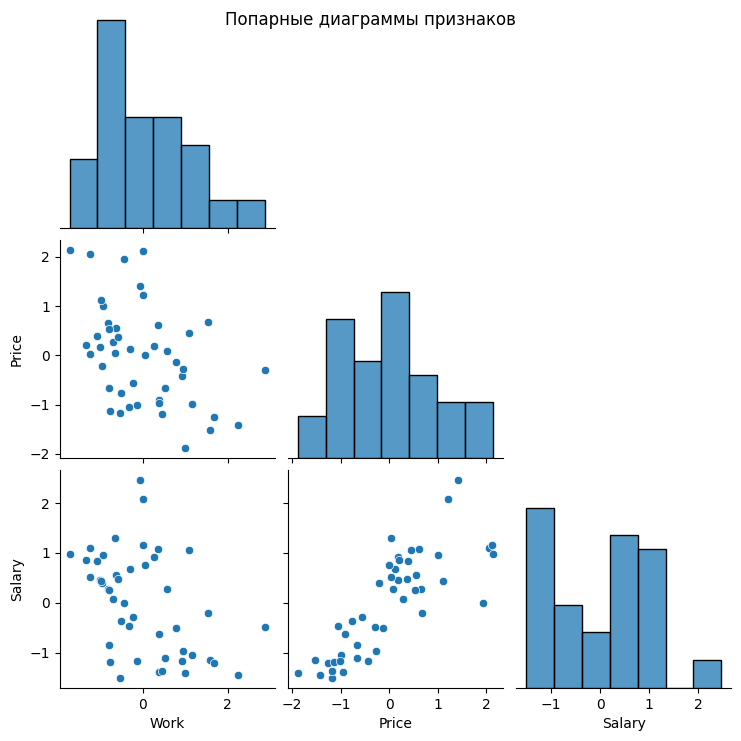

In [16]:
pairs(df_scaled)

Результаты раздела:
- Пропуски были заменены на "-9999" - отбросили 2 строки. осталось 46 строк с данными
- Есть сильная корреляция цен и зарплат
- Выполнили стандартизацию
- Сразу так кластеров не видно, мб на графике Salary/Price можно провести линию между 2 группами точек

# Выбор количества кластеров
Попробуем увидеть число кластеров  
Для визуализации всех данных на одном графике применим мой любимый метод - PCA

In [17]:
# PCA - объясняемая дисперсия
def pca_var(df: pd.DataFrame, comp: int=2):
    X = df[NUM_COLS].to_numpy()
    pca_full = PCA().fit(X)
    return np.cumsum(pca_full.explained_variance_ratio_)

# Для начала посмотрим насколько много дисперсии объясняется 2 компонентами
# Сведение до 2 компонент объясняет 93% дисперсии
print("Доля объяснения: ", pca_var(df_scaled))

Доля объяснения:  [0.72006788 0.9346159  1.        ]


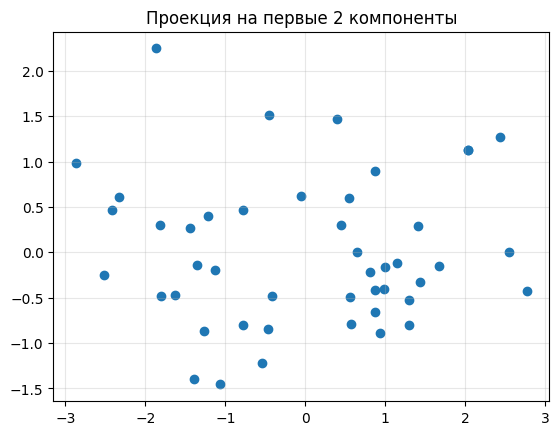

In [18]:
# Сведение к 2 главным компонентам
def pca_fit(df: pd.DataFrame, comp=2):
    pca = PCA(n_components=comp)
    X = df[NUM_COLS].to_numpy()
    X_pca = pca.fit_transform(X)
    return X_pca

# Отображения 2 главных компонент
def pca_plot(df: pd.DataFrame, comp: int=2):
    X_pca = pca_fit(df)
    plt.scatter(X_pca[:, 0], X_pca[:, 1])
    plt.title("Проекция на первые 2 компоненты")
    plt.grid(True, alpha=0.3)

# Сводим к 2 компонентам и отобразим на графике
pca_plot(df_scaled)

Выводы раздела:
- 2 компоненты отражают 93% дисперсии
- Видно 2 больших кластера
- Сверху видно отдельную точку - возможно выброс
- Справа 4 точки - возможно выбросы, или 1 или 2 кластера
- Итого 2-4 кластера

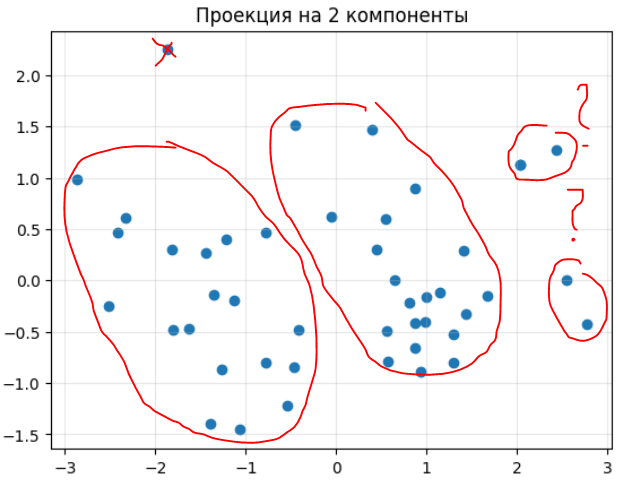

# Иерархический анализ
Построим дендрограммы, проверим число кластеров

Расстояния между объектами - посмотрим евклидово:
- Евклидово - наиболее логичное
- Манхэттенское - более устойчиво к выбросам, но мы уже избавились от выбросов
- Косинусное здесь не применимо, потому что оно смотрит на углы между векторами
- Хеммингово - для бинарных признаков

Расстояния между кластерами - проверим все:
- Single - минимальное расстояние между кластерами, находит вытянутые кластеры
- Complete - максимальное расстояние между кластерами
- Average - усреднённое расстояние между кластерами
- Ward - минимизирует внутрикластерную дисперсию

Количество кластеров буду подбирать, пока две большие группы не разрежутся или есть большие вертикальные линии

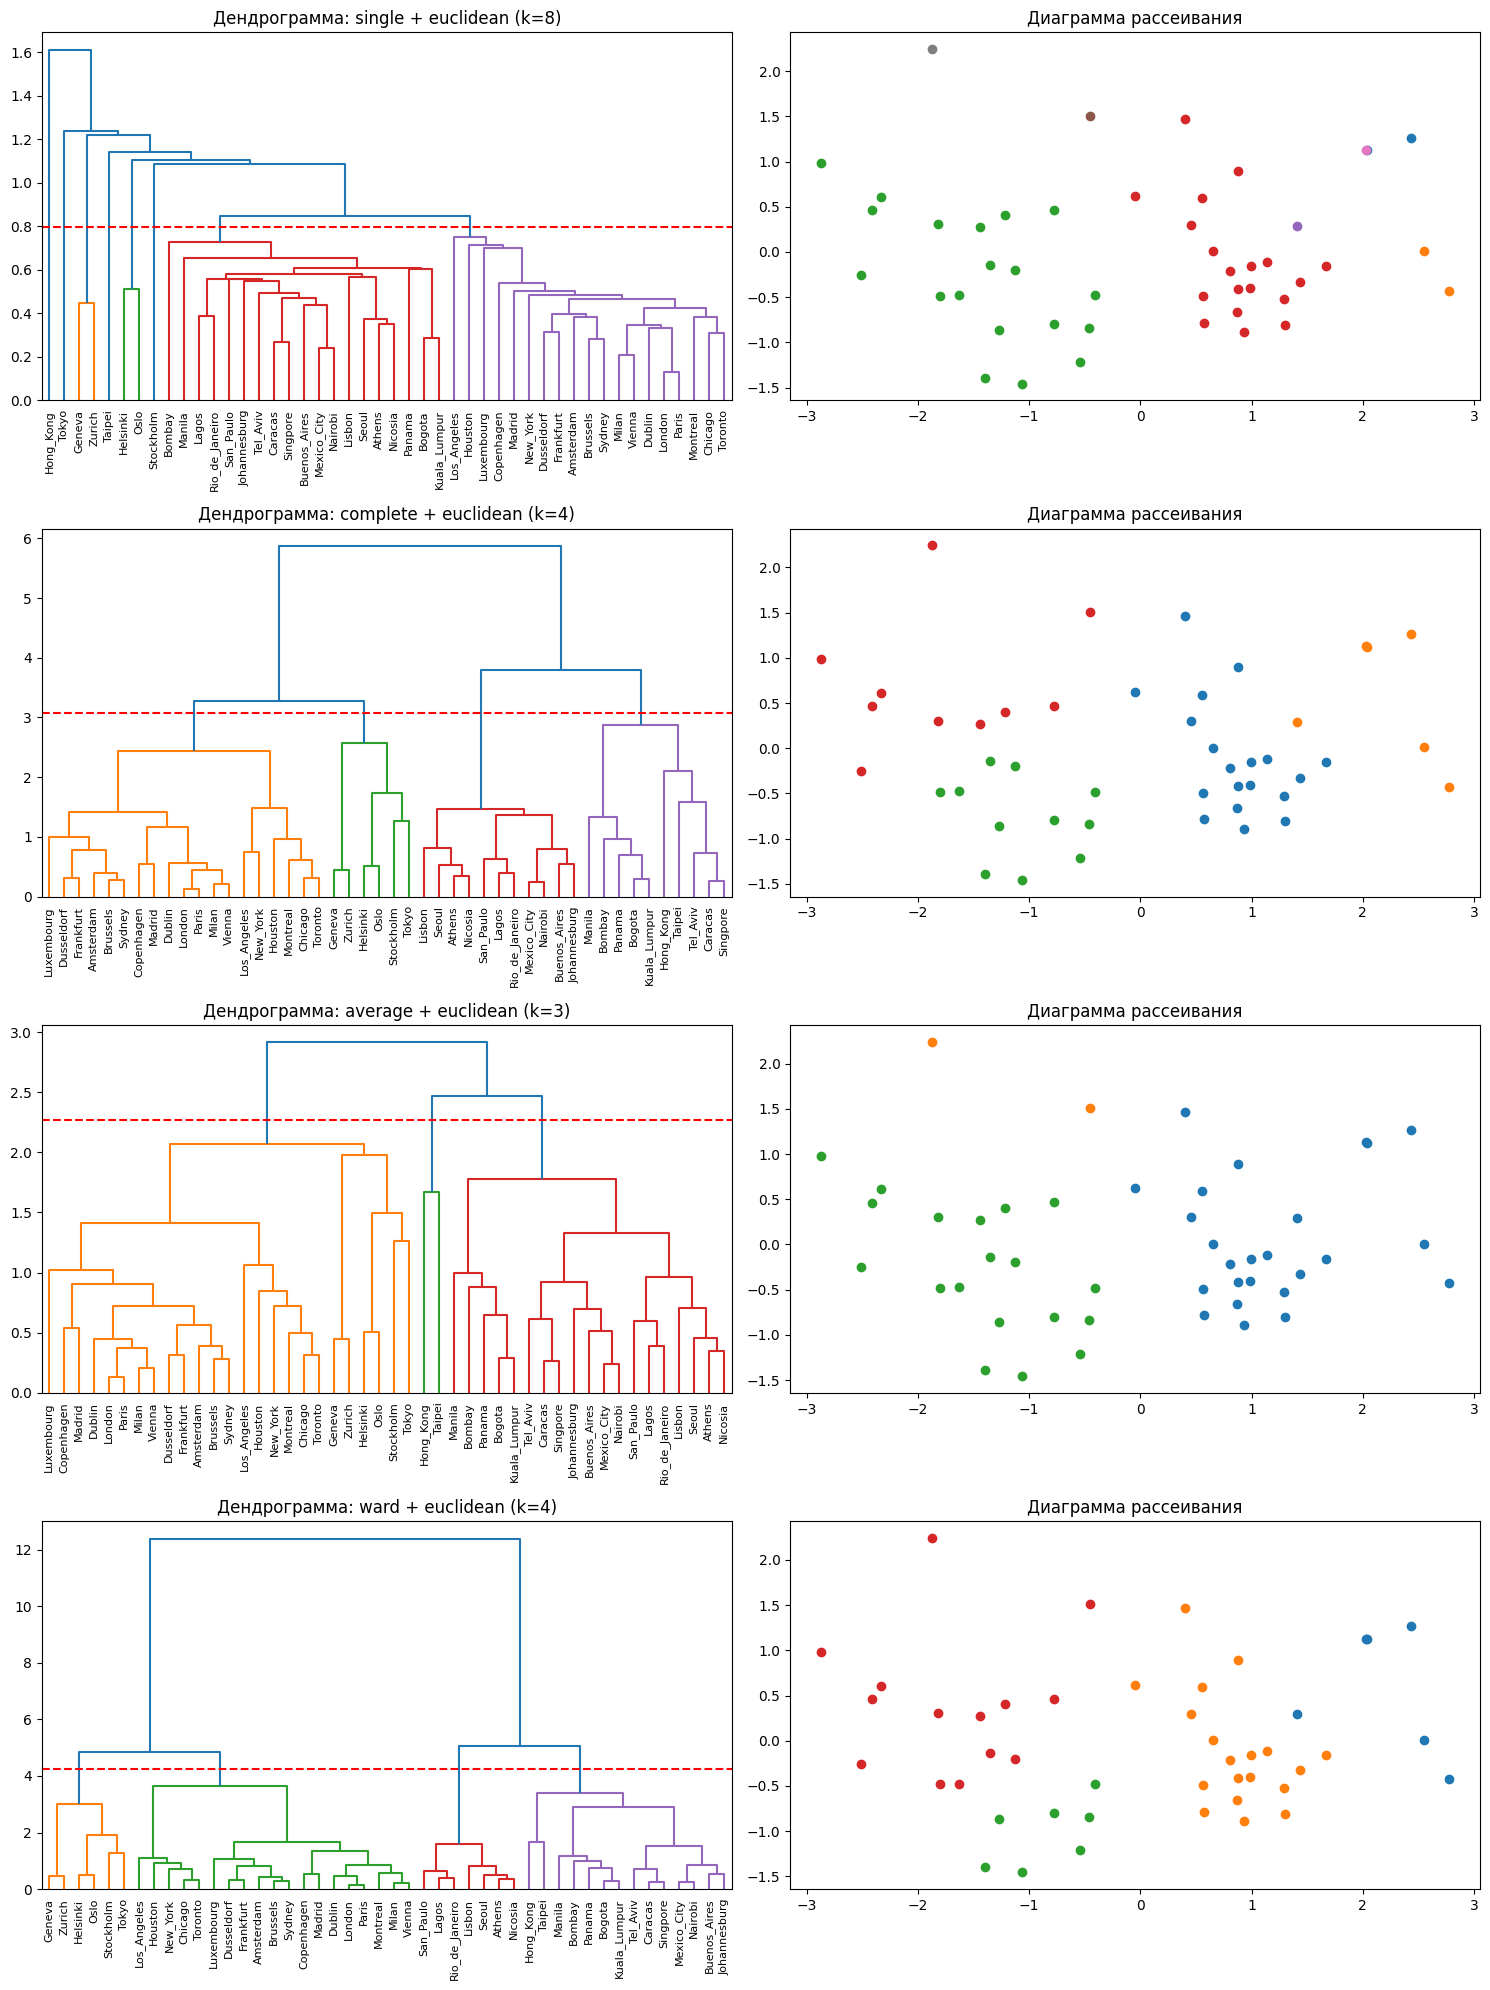

In [19]:
# Разделение на кластеры по дендрограмме
def get_clusters(df: pd.DataFrame, method: str, metric: str, k: int):
    X = df[NUM_COLS].to_numpy()
    # Процесс объединения кластеров по выбранному методу
    link = linkage(X, method=method, metric=metric)
    # Метки кластеров
    cl_labels = fcluster(link, t=k, criterion="maxclust")
    return link, cl_labels

# Построение дендрограммы
def plot_dendrogram(df: pd.DataFrame, method: str, metric: str, k: int, ax):
    cities = df[NAME_COL].tolist()
    link, cl_labels = get_clusters(df, method, metric, k)
    # Диаграмма
    h = (link[-k, 2] + link[-k+1, 2]) / 2
    dendrogram(link, ax=ax, color_threshold=h, labels=cities)
    ax.set_title(f"Дендрограмма: {method} + {metric} (k={k})")
    # Разрез на кластеры
    ax.axhline(y=h, color="red", linestyle="--")
    return cl_labels

# Отображение кластеров на графике
def plot_clusters(df: pd.DataFrame, cl_labels: np.ndarray, ax):
    X_pca = pca_fit(df)
    for cl in sorted(set(cl_labels)):
        mask = (cl_labels == cl)
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1])
        ax.set_title(f"Диаграмма рассеивания")


# Зададим перебираемые методы объединения кластеров, метрику
# и количество кластеров
linkages = ["single", "complete", "average", "ward"]
metric = "euclidean"
clusters = [8, 4, 3, 4]

fig, axes = plt.subplots(4, 2, figsize=(15, 20))
for i, (k, l) in enumerate(zip(clusters, linkages)):
    cl_clusters = plot_dendrogram(df_scaled, l, metric, k, axes[i, 0])
    plot_clusters(df_scaled, cl_clusters, axes[i, 1])

plt.tight_layout()

Выводы раздела:
- В зависимости от метода объединения кластеров дендрограмма будет указыват на разное число кластеров
- Пока что основная версия - 4 кластера
- Ward и Complete помог увидеть 4 кластера, которые не были видны до этого
- Single помог найти много городов, которые потенциально являются выбросами

# K-Means
- Применим метод K-Means и разобьём на 2-5 кластеров
- Проверим метрики локтя, Silhouette, Calinski–Harabasz, Davies–Bouldin
- Посмотрим средние значения по кластерам
- Сравним с выводами дендрограммы

# Интерпретация кластеров
Попробуем интерпретировать кластеры, полученные дендрограммой

In [20]:
# Средние значения по числовым столбцам для каждого кластера
def cluster_stats(df: pd.DataFrame, cl_labels: np.ndarray):
    tmp = df.copy()
    tmp["cluster"] = cl_labels

    stats = tmp.groupby("cluster")[NUM_COLS].mean().round(2)
    stats.insert(0, "n", tmp.groupby("cluster").size())
    stats["cities"] = tmp.groupby("cluster")[NAME_COL].apply(lambda s: ", ".join(map(str, s)))
    return stats


Single - находит выбросы.  
Группы 1-3, 6-8 содержат <= 2 элемента, которые отличаются от основных групп.  
3 - Высокая нагрузка, очень низкие цены и зарплаты. Работяги  
4 - Низкая нагрузка, высокие цены и зарплаты. Мажоры


In [21]:
ind = 0
l = linkages[ind]
k = clusters[ind]
print(f"Таблица средних значений для {l} + {metric}")
link, cl_labels = get_clusters(df_scaled, l, metric, k)
stats = cluster_stats(df_scaled, cl_labels)
display(stats)

Таблица средних значений для single + euclidean


,n,Work,Price,Salary,cities
cluster,,,,,
1,2,-0.03,1.32,2.27,"Geneva, Zurich"
2,2,-1.48,2.10,1.05,"Helsinki, Oslo"
3,19,0.46,-0.94,-1.01,"Athens, Bogota, Bombay, Buenos_Aires, Caracas,..."
4,19,-0.51,0.35,0.64,"Amsterdam, Brussels, Chicago, Copenhagen, Dubl..."
5,1,-0.43,1.95,-0.01,Stockholm
6,1,1.54,0.67,-0.21,Taipei
7,1,0.00,2.12,1.16,Tokyo
8,1,2.87,-0.30,-0.48,Hong_Kong


Complete - 4 группы  
1 - Низкая нагрузка, высокие цены и зарплаты. Мажоры  
2 - Низкая нагрузка, очень высокие цены и зарплаты. Золотые воротнички  
3 - Средняя нагрузка, очень низкие цены и зарплаты. Работяги  
4 - Очень высокая нагрузка, низкие цены и очень низкие зарплаты. Бедные трудоголики  

In [22]:
ind = 1
l = linkages[ind]
k = clusters[ind]
print(f"Таблица средних значений для {l} + {metric}")
link, cl_labels = get_clusters(df_scaled, l, metric, k)
stats = cluster_stats(df_scaled, cl_labels)
display(stats)

Таблица средних значений для complete + euclidean


,n,Work,Price,Salary,cities
cluster,,,,,
1,19,-0.51,0.35,0.64,"Amsterdam, Brussels, Chicago, Copenhagen, Dubl..."
2,6,-0.58,1.82,1.30,"Geneva, Helsinki, Oslo, Stockholm, Tokyo, Zurich"
3,11,-0.14,-0.91,-0.94,"Athens, Buenos_Aires, Johannesburg, Lagos, Lis..."
4,10,1.47,-0.75,-0.96,"Bogota, Bombay, Caracas, Hong_Kong, Kuala_Lump..."


Average - 3 группы  
1 - Низкая нагрузка, высокие цены и зарплаты. Мажоры   
2 - Очень высокая нагрузка, средние цены и низкие зарплаты. Трудоголики  
3 - Высокая нагрузка, очень низкие цены и зарплаты. Работяги

In [23]:
ind = 2
l = linkages[ind]
k = clusters[ind]
print(f"Таблица средних значений для {l} + {metric}")
link, cl_labels = get_clusters(df_scaled, l, metric, k)
stats = cluster_stats(df_scaled, cl_labels)
display(stats)

Таблица средних значений для average + euclidean


,n,Work,Price,Salary,cities
cluster,,,,,
1,25,-0.53,0.70,0.80,"Amsterdam, Brussels, Chicago, Copenhagen, Dubl..."
2,2,2.20,0.19,-0.34,"Hong_Kong, Taipei"
3,19,0.46,-0.94,-1.01,"Athens, Bogota, Bombay, Buenos_Aires, Caracas,..."


Ward - 4 группы  
1 - Низкая нагрузка, очень высокие цены и зарплаты. Золотые воротнички  
2 - Низкая нагрузка, средние цены и высокие зарплаты. Мажоры  
3 - Низкая нагрузка, очень низкие цены и зарплаты. Лентяи  
4 - Очень высокая нагрузка, очень низкие цены и зарплаты. Бедные трудоголики  

In [24]:
ind = 3
l = linkages[ind]
k = clusters[ind]
print(f"Таблица средних значений для {l} + {metric}")
link, cl_labels = get_clusters(df_scaled, l, metric, k)
stats = cluster_stats(df_scaled, cl_labels)
display(stats)

Таблица средних значений для ward + euclidean


,n,Work,Price,Salary,cities
cluster,,,,,
1,6,-0.58,1.82,1.30,"Geneva, Helsinki, Oslo, Stockholm, Tokyo, Zurich"
2,19,-0.51,0.35,0.64,"Amsterdam, Brussels, Chicago, Copenhagen, Dubl..."
3,7,-0.47,-0.91,-0.83,"Athens, Lagos, Lisbon, Nicosia, Rio_de_Janeiro..."
4,14,1.17,-0.80,-1.01,"Bogota, Bombay, Buenos_Aires, Caracas, Hong_Ko..."


# Выводы
- Пропуски были закодированы как -9999. Удалены две строки (Каир и Джакарта), в которых отсутствовали два из трёх показателей. Итоговая выборка — 46 городов.
- Обнаружена сильная положительная корреляция между индексом цен и индексом зарплат: в городах с высокими доходами выше и стоимость жизни.
- На проекции на 2 главные компоненты видны две крупные группы и несколько отдельных точек, что указывает на наличие как минимум двух кластеров и возможных выбросов.
- В зависимости от выбранного метода кластеризации группировка происходила по-разному, что позволяло посмотреть на данные с разных сторон.
    - Single чувствителен к выбросам - городам с уникальными экономическими профилями.
- Можно интерпретировать разные группы: работяги, трудоголики, мажоры, золотые воротнички.
- Гипотезы
    - Города можно разбить на кластеры.
    - Присутствуют сильно отличающиеся города.